# Our method at depth: 2-task multi-MNIST with 2 to 4 hidden layers

With more hidden layers, does our method still do as well as this architecture allows? We train it on deeper
networks, fully connected and block-sparse, and compare it with SGD tuned on each network at each depth.

**Problem.** 2-task multi-MNIST exactly as in `../05_multi_mnist.ipynb`: each sample concatenates 2 independently drawn
training images (14×14, averaged 2×2 blocks; each pixel centered, all scaled by one standard deviation), and each
task's target is its own image's label. Every 1000 steps, one task (chosen at random) gets a new random mapping from
digits to labels. The loss is the sum of each task's softmax cross-entropy.

**Networks.** 3, 4 and 5 weight layers: 392 inputs → 2, 3 or 4 hidden layers of 20 LTUs → 20 linear outputs (2 groups
of 10 logits), every layer with a bias.
- *Fully connected*: every unit reads every unit of the layer below.
- *Block-sparse*: every layer is block-diagonal, so each task has its own column of 10 units through all hidden layers:
  the first reads only its task's image, and the last feeds only its task's logits (05's ideal connectivity, deeper).

**Learners.**
- *Ours*, at depth. Every hidden layer is centered: it sends $h - m$, $m$ its own running mean firing rates (rate
  $10^{-3}$, starting at 1/2). Every hidden layer's input weights are backward centered as in 05: each one's derivative
  is $\sigma'(z)\,x - \mathbb{E}[\sigma'(z)\,x]$, with a running mean per layer, $x$ that layer's input including the
  bias (the centered output of the layer below). Every hidden layer's input weights start at $U(-\alpha_0, \alpha_0)$;
  output weights and biases start at 0. Autostep ($\alpha_0 = 10^{-8}$, meta step-size 0.01, $\tau = 10^4$) treats
  each layer as its own linear problem, its source values that layer's input.
- *SGD*, the standard setup: raw hidden units $h$, LeCun-uniform input weights at every hidden layer, output weights and
  biases at 0, one constant step size. It is tuned separately at each depth and on each network: 5 seeds per step
  size, over powers of 2, by the accuracy below. Each grid is extended one power of 2 at a time past whichever edge
  holds its best value, until the best has a worse value on both sides.

Per-layer backward centering removes the mean push on each layer's own input weights exactly (`../01_distractors.ipynb`,
3c). The gradient passed down to lower layers is centered only up to a covariance term: through upper unit $j$, a
lower weight $w'_{ki}$ gets $\delta_j\,\sigma'(z_j)\,w_{jk}\,(\sigma'(z'_k)\,x'_i - \mathbb{E}[\sigma'(z'_k)\,x'_i])$,
whose mean under a constant error $\delta_j$ is $\delta_j\,w_{jk}\,\mathrm{Cov}(\sigma'(z_j), \sigma'(z'_k)\,x'_i)$,
not 0. But with all weights near $10^{-8}$ early, the gradients reaching lower layers are tiny in the phase where the
mean push mattered (`../01_distractors.ipynb`, 3b).

At each depth: ours and SGD (at its best step size for that network) on both networks. 1000k steps;
seed $s$ gives every run the same initial-weight draw, images and label changes.

**Hypotheses**, on the online accuracy (over every task) averaged over the last 10% of training, as gaps on paired
seeds (mean ± 2 SE):
- **H1**, depth does not bring back mixing: at every depth, ours fully connected is at most 1 percentage point below
  ours block-sparse.
- **H2**, ours does as well as the architecture allows: at every depth, ours block-sparse is at most 1 percentage point
  below SGD block-sparse.
- **H3**, density also costs SGD: at every depth, SGD fully connected is more than 1 percentage point below SGD
  block-sparse.

**Diagnostics**, fixed in advance:
1. *Centering at depth*: for ours, per hidden layer, the mean over units of $|$true firing rate $- m|$ over the first
   20k steps, as in 3b of `../01_distractors.ipynb`. The true rate is measured every 100 steps on 4096 fixed probe
   samples, fed through the current network (with its running means).
2. *Path purity*, end to end: the share of all input → … → output path weight (the product of $|w|$ along the path)
   that starts and ends in the same task. 1 means no path crosses tasks; 1/2 that the paths mix the tasks evenly. It
   is 1 by construction on the block-sparse network. Pooling over all paths means a task with almost no paths barely
   counts.
3. *Per-task accuracy*: each task's online accuracy, recorded per window for every run. Reported per run as each
   task's accuracy over the last 10% of training (mean over seeds), and the number of seeds in which a task stays
   near chance (below 15% over the last 10%; chance is 10%).

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

sns.set_theme('notebook', 'white')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 2
N_PIXELS = 14 * 14                   # MNIST downsampled from 28x28 by averaging 2x2 blocks
N_CLASSES = 10
PERMUTE_PERIOD = 2000 // N_TASKS     # steps between label changes, each of one task chosen at random

# --- Networks ---
DEPTHS = (3, 4, 5)                   # weight layers: 2, 3 and 4 hidden layers
N_HIDDEN_PER_TASK = 10               # every hidden layer has 10 units per task, 20 in total

# --- Autostep (ours) ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means

# --- SGD ---
SGD_EXPONENTS = range(-8, 1)         # each network's sweep starts at 2^-8 ... 2^0, and grows past an edge with its best
SWEEP_SEEDS = 5                      # seeds per step size in the sweeps

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 5
N_WINDOWS = 250                      # each window records its mean loss and accuracy, and the path purity at its end

# --- Diagnostics ---
EARLY_STEPS = 20_000                 # firing rates against running means over the first 20k steps ...
EARLY_EVERY = 100                    # ... measured every 100 steps ...
N_PROBE = 4096                       # ... on this many fixed probe samples, as in 01_distractors.ipynb
NEAR_CHANCE = 0.15                   # a task below this accuracy over the last 10% stays near chance (10%)

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # accuracy is compared over the last 10% of training ...
ACCURACY_TOLERANCE = 0.01            # ... with this tolerance (1 percentage point)

In [3]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
images = np.asarray(mnist.data, dtype=np.float32).reshape(-1, 14, 2, 14, 2).mean((2, 4)).reshape(-1, N_PIXELS) / 255.0
IMAGES = jnp.asarray((images - images.mean(0)) / images.std())     # per-pixel centered, one global scale
DIGITS = jnp.asarray(np.asarray(mnist.targets))


class Stream(NamedTuple):
    key: jax.Array
    step: jax.Array
    label_maps: jax.Array     # (task, digit): each task's current label for each digit


def init_stream(key):
    return Stream(key, jnp.array(0), jnp.tile(jnp.arange(N_CLASSES), (N_TASKS, 1)))


def next_sample(stream):
    # One sample: an independent training image per task, concatenated, and each task's label. Every PERMUTE_PERIOD
    # steps, one task chosen at random first gets a new random label mapping.
    key, task_key, map_key, image_key = jax.random.split(stream.key, 4)
    step = stream.step + 1
    changes = (step % PERMUTE_PERIOD == 0) & (jnp.arange(N_TASKS) == jax.random.randint(task_key, (), 0, N_TASKS))
    label_maps = jnp.where(changes[:, None], jax.random.permutation(map_key, N_CLASSES)[None], stream.label_maps)
    index = jax.random.randint(image_key, (N_TASKS,), 0, IMAGES.shape[0])
    labels = label_maps[jnp.arange(N_TASKS), DIGITS[index]]
    return Stream(key, step, label_maps), (IMAGES[index].reshape(-1), labels)

In [4]:
NETWORKS = ('fully connected', 'block-sparse')


def network_masks(n_layers, network):
    # Each layer's mask, shaped like its weight matrix (units, inputs + 1); the last column reads the constant-1 input.
    # Block-sparse: a unit reads only the units of its own task in the layer below.
    sizes = [N_PIXELS] + [N_HIDDEN_PER_TASK] * (n_layers - 1) + [N_CLASSES]       # per task, from inputs to outputs
    tasks = [np.repeat(np.arange(N_TASKS), n) for n in sizes]
    return [np.concatenate([(out[:, None] == inp[None, :]) | (network == 'fully connected'),
                            np.ones((len(out), 1), bool)], 1)
            for inp, out in zip(tasks[:-1], tasks[1:])]


for n_layers in DEPTHS:
    for network in NETWORKS:
        weights = ', '.join(f'{m[:, :-1].sum():,}' for m in network_masks(n_layers, network))
        print(f'{n_layers} layers, {network}: {weights} weights')

3 layers, fully connected: 7,840, 400, 400 weights
3 layers, block-sparse: 3,920, 200, 200 weights
4 layers, fully connected: 7,840, 400, 400, 400 weights
4 layers, block-sparse: 3,920, 200, 200, 200 weights
5 layers, fully connected: 7,840, 400, 400, 400, 400 weights
5 layers, block-sparse: 3,920, 200, 200, 200, 200 weights


## Learners

In [5]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: list                   # each layer's weights; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState            # Autostep's state (unused by SGD)
    hidden_mean: list         # each hidden layer's running mean firing rates
    hidden_slope: list        # each hidden layer's running mean of sigma'(z) x, its derivative w.r.t. each input weight


def init_learner(key, masks, ours):
    # Every hidden layer's input weights: U(-INIT_STEP_SIZE, INIT_STEP_SIZE) for ours, LeCun uniform over each unit's
    # inputs for SGD. Both scale the same draw. Biases and output weights start at 0.
    w = []
    for layer_key, mask in zip(jax.random.split(key, len(masks) - 1), masks[:-1]):
        bound = INIT_STEP_SIZE if ours else jnp.sqrt(3.0 / mask[:, :-1].sum(1, keepdims=True))
        w.append((jax.random.uniform(layer_key, mask.shape, minval=-1.0, maxval=1.0) * bound * mask).at[:, -1].set(0.0))
    w.append(jnp.zeros(masks[-1].shape))
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs (the centered units below, for ours), 1/4 for the bias.
    return Learner(w, OPTIMIZER.init(w), [jnp.full(m.shape[0], 0.5) for m in masks[:-1]],
                   [jnp.zeros(m.shape).at[:, -1].set(0.25) for m in masks[:-1]])


def forward(w, x, learner, masks, ours):
    # Returns the prediction, each layer's source values (its input, what Autostep normalizes by), and the new running
    # means of every hidden layer.
    sources, means, slopes = [], [], []
    for layer, mask, mean, slope in zip(w[:-1], masks[:-1], learner.hidden_mean, learner.hidden_slope):
        x = jnp.append(x, 1.0)
        sources.append(x[None])
        layer = layer * mask
        z = layer @ x
        h = ltu(z)

        # Running means, updated with this sample before they are used. No gradient flows through them.
        mean = mean + EMA_RATE * (jax.lax.stop_gradient(h) - mean)
        sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))  # the LTU's surrogate slope
        slope = slope + EMA_RATE * (sigma_prime[:, None] * jax.lax.stop_gradient(x)[None, :] - slope)
        if ours:
            # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope.
            # The correction leaves the value unchanged.
            correction = jnp.sum(slope * layer, axis=1)
            h = h - mean - correction + jax.lax.stop_gradient(correction)
        means.append(mean)
        slopes.append(slope)
        x = h

    x = jnp.append(x, 1.0)
    sources.append(x[None])
    return (w[-1] * masks[-1]) @ x, (sources, means, slopes)


def learner_step(learner, x, labels, masks, ours, step_size=None):
    # One online update on the summed softmax cross-entropy of every task: Autostep for ours, SGD with `step_size`
    # otherwise. Returns the new learner, the loss and whether each task was classified correctly.
    def loss_fn(w):
        logits, aux = forward(w, x, learner, masks, ours)
        logits = logits.reshape(N_TASKS, N_CLASSES)
        return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), (aux, logits)

    (loss, ((sources, mean, slope), logits)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    if ours:
        updates, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.w)
    else:
        updates, opt = [-step_size * g for g in grads], learner.opt
    w = [w + u for w, u in zip(learner.w, updates)]
    return Learner(w, opt, mean, slope), loss, (logits.argmax(-1) == labels).astype(jnp.float32)

## Training

In [6]:
final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)


def final_accuracy(res):
    return res['accuracy'][:, final].mean(1)                 # each seed's accuracy over the last FINAL_FRACTION


def path_purity(w):
    # The share of all input -> ... -> output path weight (the product of |w| along the path) that starts and ends in
    # the same task. Biases are left out. The paths are summed layer by layer, rescaled to a total of 1 each time,
    # which leaves the share unchanged and keeps products of many near-zero weights from underflowing.
    paths = jnp.abs(w[0][:, :-1]).reshape(-1, N_TASKS, N_PIXELS).sum(-1)          # (unit, input task)
    for layer in w[1:]:
        paths = jnp.abs(layer[:, :-1]) @ (paths / jnp.maximum(paths.sum(), 1e-30))
    paths = paths.reshape(N_TASKS, N_CLASSES, N_TASKS).sum(1)                      # (output task, input task)
    return jnp.trace(paths) / jnp.maximum(paths.sum(), 1e-30)


def train(key, stream, masks, ours, step_size=None):
    # Step 1 on its own, then NUM_STEPS online steps in windows. Returns the mean loss and accuracy (overall and per
    # task) of every window, and the path purity at its end.
    def one_step(carry, _):
        learner, stream = carry
        stream, (x, labels) = next_sample(stream)
        learner, loss, accuracy = learner_step(learner, x, labels, masks, ours, step_size)
        return (learner, stream), (loss, accuracy)

    def window(carry, _):
        carry, (loss, accuracy) = jax.lax.scan(one_step, carry, length=NUM_STEPS // N_WINDOWS)
        return carry, {'loss': loss.mean(), 'accuracy': accuracy.mean(), 'task accuracy': accuracy.mean(0),
                       'purity': path_purity(carry[0].w)}

    stream, (x, labels) = next_sample(stream)
    learner = learner_step(init_learner(key, masks, ours), x, labels, masks, ours, step_size)[0]
    return jax.lax.scan(window, (learner, stream), length=N_WINDOWS)[1]


def seeds(n):
    # The first n seeds' init keys and streams. Seed s uses init key s and stream s in every run (split 30 ways, as in
    # 05), so runs are paired across networks, learners and notebooks.
    keys = jax.random.split(jax.random.PRNGKey(0), 30)[:n]
    return keys, jax.vmap(init_stream)(jax.random.split(jax.random.PRNGKey(1), 30)[:n])


def train_all(n_layers, ours, networks, step_sizes, n_seeds):
    # Trains on each network named in `networks` (repeats allowed) with the step size at the same place in `step_sizes`
    # (SGD's; ours ignores it), on each of the first n_seeds seeds, all vmapped into one scan with the masks as data.
    # Returns records shaped (network, seed, window).
    masks = [jnp.asarray(np.stack(m)) for m in zip(*[network_masks(n_layers, network) for network in networks])]
    keys, streams = seeds(n_seeds)
    each = lambda a: jnp.repeat(a, n_seeds, axis=0)                               # each network on every seed ...
    tile = lambda a: jnp.tile(a, (len(networks),) + (1,) * (a.ndim - 1))          # ... and every seed for each network
    train_each = jax.vmap(lambda key, stream, masks, step_size: train(key, stream, masks, ours, step_size))
    records = jax.jit(train_each)(tile(keys), jax.tree.map(tile, streams), [each(m) for m in masks],
                                  each(jnp.asarray(step_sizes, dtype=jnp.float32)))
    return jax.tree.map(lambda a: np.asarray(a).reshape(len(networks), n_seeds, *a.shape[1:]), records)


def run(n_layers, ours, step_sizes=(0.0, 0.0)):
    # Trains ours, or SGD with `step_sizes` (one per network in NETWORKS), on both networks on every seed, in one scan.
    # Returns {network: per-seed records}: loss, accuracy, task accuracy and purity (seed, window).
    records = train_all(n_layers, ours, NETWORKS, step_sizes, N_SEEDS)
    return {network: jax.tree.map(lambda a: a[i], records) for i, network in enumerate(NETWORKS)}


def tune_sgd(n_layers):
    # SGD's sweep on both networks over SGD_EXPONENTS, on the first SWEEP_SEEDS seeds, in one scan. Each network's grid
    # is then extended one power of 2 at a time past whichever edge holds its best accuracy, until its best has a worse
    # value on both sides. Returns {network: {exponent: records}} and {network: best exponent}.
    def sweep(configs):                          # {(network, exponent): records} for every pair in `configs`
        records = train_all(n_layers, False, [n for n, _ in configs], [2.0 ** e for _, e in configs], SWEEP_SEEDS)
        return {c: jax.tree.map(lambda a: a[i], records) for i, c in enumerate(configs)}

    results = sweep([(network, e) for network in NETWORKS for e in SGD_EXPONENTS])
    sweeps, best = {}, {}
    for network in NETWORKS:
        while True:
            exponents = sorted(e for n, e in results if n == network)
            best[network] = max(exponents, key=lambda e: final_accuracy(results[network, e]).mean())
            if best[network] not in (exponents[0], exponents[-1]):
                break
            results |= sweep([(network, best[network] + (-1 if best[network] == exponents[0] else 1))])
        sweeps[network] = {e: results[network, e] for e in exponents}
    return sweeps, best

In [7]:
PROBE = IMAGES[jax.random.randint(jax.random.PRNGKey(2), (N_PROBE, N_TASKS), 0, IMAGES.shape[0])].reshape(N_PROBE, -1)


def rate_gaps(learner, masks):
    # Each hidden layer's mean over units of |true firing rate - m|, the true rate measured on the probe samples fed
    # through the current network (each layer sends h - m to the next).
    x, gaps = PROBE, []
    for layer, mask, mean in zip(learner.w[:-1], masks[:-1], learner.hidden_mean):
        h = (jnp.append(x, jnp.ones((N_PROBE, 1)), axis=1) @ (layer * mask).T > 0).astype(jnp.float32)
        gaps.append(jnp.abs(h.mean(0) - mean).mean())
        x = h - mean
    return jnp.stack(gaps)


def early_dynamics(n_layers, network):
    # Ours' first EARLY_STEPS steps on every seed (the same steps as in run()), recording rate_gaps every EARLY_EVERY
    # steps. Returns (seed, time, hidden layer).
    masks = network_masks(n_layers, network)

    def train_short(key, stream):
        def one_step(carry, _):
            learner, stream = carry
            stream, (x, labels) = next_sample(stream)
            return (learner_step(learner, x, labels, masks, True)[0], stream), None

        def window(carry, _):
            carry, _ = jax.lax.scan(one_step, carry, length=EARLY_EVERY)
            return carry, rate_gaps(carry[0], masks)

        return jax.lax.scan(window, (init_learner(key, masks, True), stream), length=EARLY_STEPS // EARLY_EVERY)[1]

    return np.asarray(jax.jit(jax.vmap(train_short))(*seeds(N_SEEDS)))

## SGD's step size

At each depth, SGD on each network, every step size in its sweep, 5 seeds each (the first 5 of the main runs'
seeds). Mean online accuracy over the last 10% of training, without error bars.

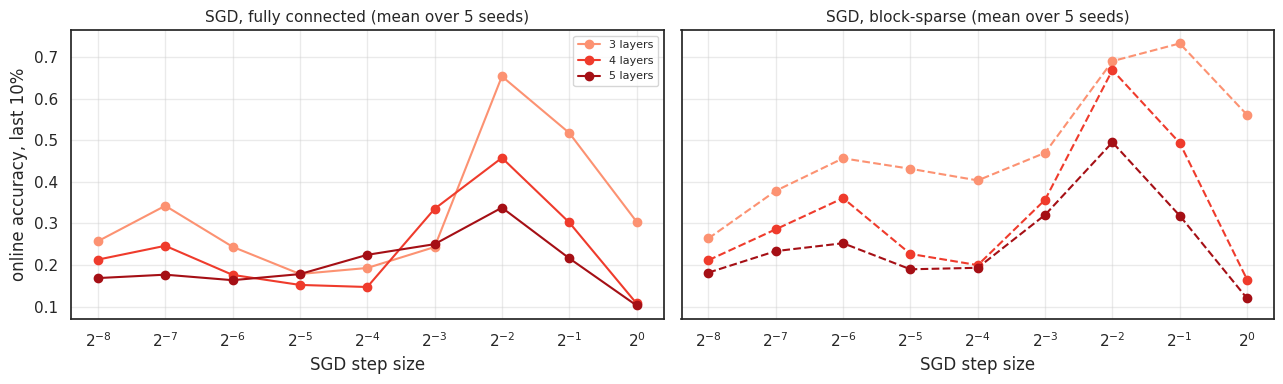

3 layers, fully connected: 2^-8 25.71%, 2^-7 34.23%, 2^-6 24.37%, 2^-5 17.83%, 2^-4 19.28%, 2^-3 24.31%, 2^-2 65.33%, 2^-1 51.73%, 2^0 30.41%; best 2^-2
3 layers, block-sparse: 2^-8 26.38%, 2^-7 37.82%, 2^-6 45.63%, 2^-5 43.12%, 2^-4 40.32%, 2^-3 46.95%, 2^-2 68.98%, 2^-1 73.24%, 2^0 56.08%; best 2^-1
4 layers, fully connected: 2^-8 21.29%, 2^-7 24.61%, 2^-6 17.62%, 2^-5 15.21%, 2^-4 14.71%, 2^-3 33.49%, 2^-2 45.74%, 2^-1 30.22%, 2^0 10.76%; best 2^-2
4 layers, block-sparse: 2^-8 21.15%, 2^-7 28.57%, 2^-6 36.06%, 2^-5 22.66%, 2^-4 19.96%, 2^-3 35.67%, 2^-2 66.84%, 2^-1 49.32%, 2^0 16.49%; best 2^-2
5 layers, fully connected: 2^-8 16.85%, 2^-7 17.67%, 2^-6 16.35%, 2^-5 17.81%, 2^-4 22.44%, 2^-3 25.00%, 2^-2 33.78%, 2^-1 21.61%, 2^0 10.28%; best 2^-2
5 layers, block-sparse: 2^-8 18.17%, 2^-7 23.34%, 2^-6 25.22%, 2^-5 18.96%, 2^-4 19.32%, 2^-3 32.04%, 2^-2 49.48%, 2^-1 31.84%, 2^0 11.97%; best 2^-2


In [8]:
sweeps, best_exponent = {}, {}
for n_layers in DEPTHS:
    sweeps[n_layers], best_exponent[n_layers] = tune_sgd(n_layers)

fig, axes = plt.subplots(1, len(NETWORKS), figsize=(13, 4), sharex=True, sharey=True)
for ax, network in zip(axes, NETWORKS):
    for n_layers, color in zip(DEPTHS, ('#fc9272', '#ef3b2c', '#a50f15')):
        sweep = sweeps[n_layers][network]
        ax.plot(list(sweep), [final_accuracy(r).mean() for r in sweep.values()], color=color, marker='o', lw=1.5,
                ls='--' if network == 'block-sparse' else '-', label=f'{n_layers} layers')
    ax.set_xlabel('SGD step size')
    ax.set_title(f'SGD, {network} (mean over {SWEEP_SEEDS} seeds)', fontsize=11)
    ax.grid(alpha=0.4)
exponents = sorted({e for by_network in sweeps.values() for sweep in by_network.values() for e in sweep})
axes[0].set_xticks(range(exponents[0], exponents[-1] + 1))
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda e, _: f'$2^{{{e:g}}}$'))
axes[0].yaxis.set_major_locator(plt.MultipleLocator(0.1))
axes[0].set_ylabel('online accuracy, last 10%')
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

for n_layers in DEPTHS:
    for network, sweep in sweeps[n_layers].items():
        accuracies = ', '.join(f'2^{e} {final_accuracy(r).mean():.2%}' for e, r in sweep.items())
        print(f'{n_layers} layers, {network}: {accuracies}; best 2^{best_exponent[n_layers][network]}')

## Main runs

Ours and SGD (at its best step size for each network) on both networks, at each depth (mean ± 2 SE over seeds).
Blue: ours; red: SGD; dashed: block-sparse.

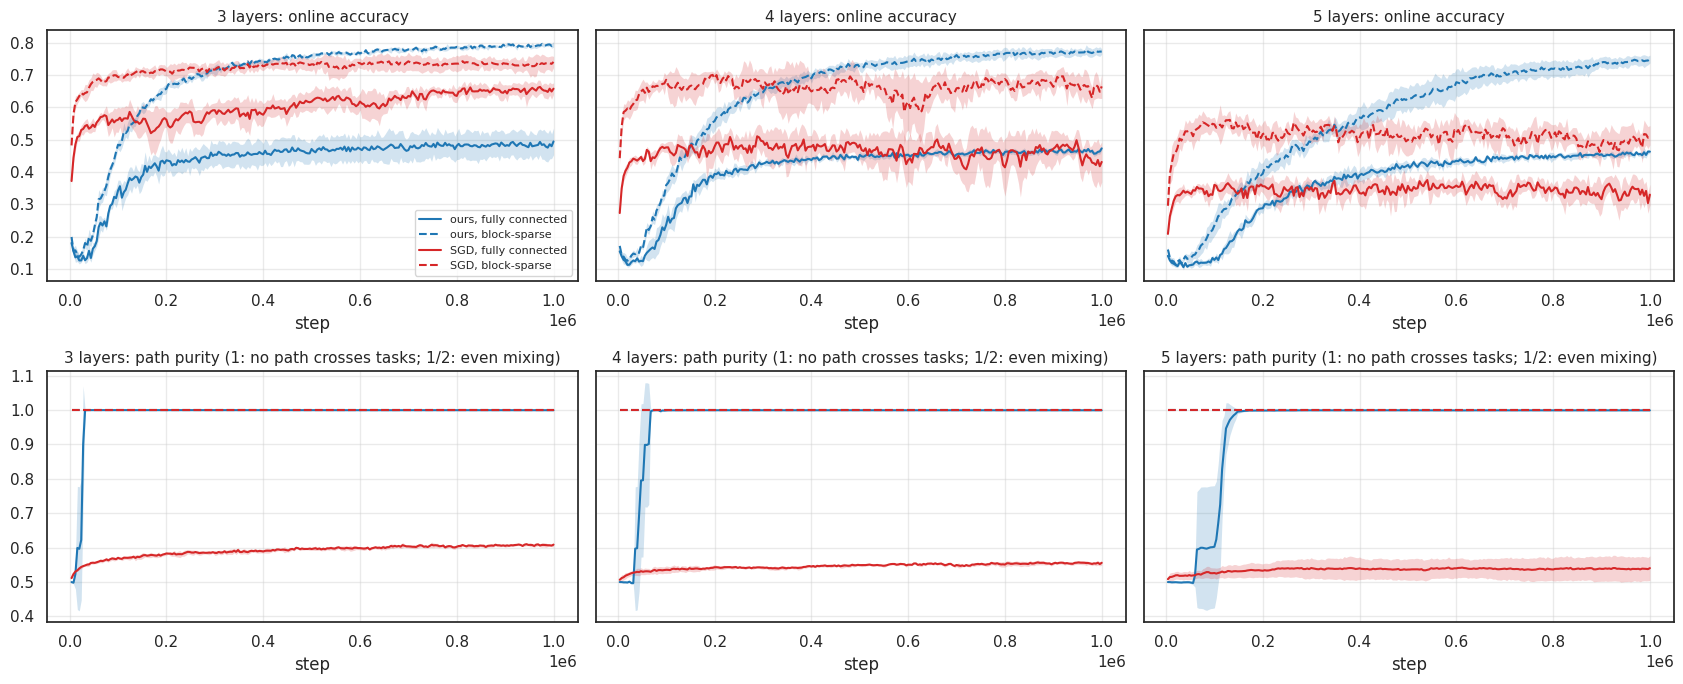

--- 3 layers (SGD step sizes: fully connected 2^-2, block-sparse 2^-1) ---
ours, fully connected   online accuracy 48.40% (tasks 53.0%, 43.8%); a task below 15% in 4 of 5 seeds
ours, block-sparse      online accuracy 79.06% (tasks 79.0%, 79.1%); a task below 15% in 0 of 5 seeds
SGD, fully connected    online accuracy 65.33% (tasks 67.4%, 63.2%); a task below 15% in 0 of 5 seeds
SGD, block-sparse       online accuracy 73.24% (tasks 70.9%, 75.6%); a task below 15% in 0 of 5 seeds
H1, ours, fully connected vs ours, block-sparse: -30.7 points (± 4.2): failed
H2, ours, block-sparse vs SGD, block-sparse: +5.8 points (± 2.5): held
H3, SGD, fully connected vs SGD, block-sparse: -7.9 points (± 3.1): held
--- 4 layers (SGD step sizes: fully connected 2^-2, block-sparse 2^-2) ---
ours, fully connected   online accuracy 46.40% (tasks 53.5%, 39.3%); a task below 15% in 5 of 5 seeds
ours, block-sparse      online accuracy 77.02% (tasks 76.9%, 77.1%); a task below 15% in 0 of 5 seeds
SGD, fully conne

In [9]:
window_ends = np.arange(1, N_WINDOWS + 1) * (NUM_STEPS // N_WINDOWS)
runs = {}
for n_layers in DEPTHS:
    ours = run(n_layers, True)
    sgd = run(n_layers, False, [2.0 ** best_exponent[n_layers][network] for network in NETWORKS])
    runs[n_layers] = {**{f'ours, {k}': v for k, v in ours.items()}, **{f'SGD, {k}': v for k, v in sgd.items()}}

fig, axes = plt.subplots(2, len(DEPTHS), figsize=(17, 7), sharey='row')
for column, n_layers in enumerate(DEPTHS):
    for row, (key, title) in enumerate([('accuracy', 'online accuracy'),
                                        ('purity', 'path purity (1: no path crosses tasks; 1/2: even mixing)')]):
        ax = axes[row, column]
        for label, res in runs[n_layers].items():
            mean, sem = res[key].mean(0), res[key].std(0) / np.sqrt(N_SEEDS)
            color = 'tab:blue' if label.startswith('ours') else 'tab:red'
            ls = '--' if label.endswith('block-sparse') else '-'
            ax.plot(window_ends, mean, color=color, ls=ls, lw=1.5, label=label)
            ax.fill_between(window_ends, mean - 2 * sem, mean + 2 * sem, color=color, alpha=0.2, lw=0)
        ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
        ax.set_xlabel('step')
        ax.set_title(f'{n_layers} layers: {title}', fontsize=11)
        ax.grid(alpha=0.4)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()


def report(runs, tests):
    # Prints every run's accuracy, each task's accuracy (mean over seeds) and the number of seeds in which a task is
    # below NEAR_CHANCE, all over the last FINAL_FRACTION. Then for each test (name, label, reference, claim) the
    # per-seed gap of `label` to `reference` (mean and 2 SE over paired seeds), and whether the claim held: 'within'
    # ACCURACY_TOLERANCE of it (at most that far below), or more than that 'below' it.
    width = max(map(len, runs))
    for label, res in runs.items():
        tasks = res['task accuracy'][:, final].mean(1)                            # (seed, task)
        print(f'{label:<{width}}   online accuracy {final_accuracy(res).mean():.2%} (tasks '
              + ', '.join(f'{a:.1%}' for a in tasks.mean(0))
              + f'); a task below {NEAR_CHANCE:.0%} in {(tasks < NEAR_CHANCE).any(1).sum()} of {len(tasks)} seeds')
    for name, label, reference, claim in tests:
        g = final_accuracy(runs[label]) - final_accuracy(runs[reference])
        ok = g.mean() >= -ACCURACY_TOLERANCE if claim == 'within' else g.mean() < -ACCURACY_TOLERANCE
        print(f'{name}, {label} vs {reference}: {100 * g.mean():+.1f} points '
              f'(± {100 * 2 * g.std() / np.sqrt(N_SEEDS):.1f}): {"held" if ok else "failed"}')


for n_layers in DEPTHS:
    step_sizes = ', '.join(f'{network} 2^{e}' for network, e in best_exponent[n_layers].items())
    print(f'--- {n_layers} layers (SGD step sizes: {step_sizes}) ---')
    report(runs[n_layers], [('H1', 'ours, fully connected', 'ours, block-sparse', 'within'),
                            ('H2', 'ours, block-sparse', 'SGD, block-sparse', 'within'),
                            ('H3', 'SGD, fully connected', 'SGD, block-sparse', 'below')])

## Diagnostic 1: centering at depth

Ours over the first 20k steps: for each hidden layer, the mean over units of $|$true firing rate $- m|$, averaged over
seeds.

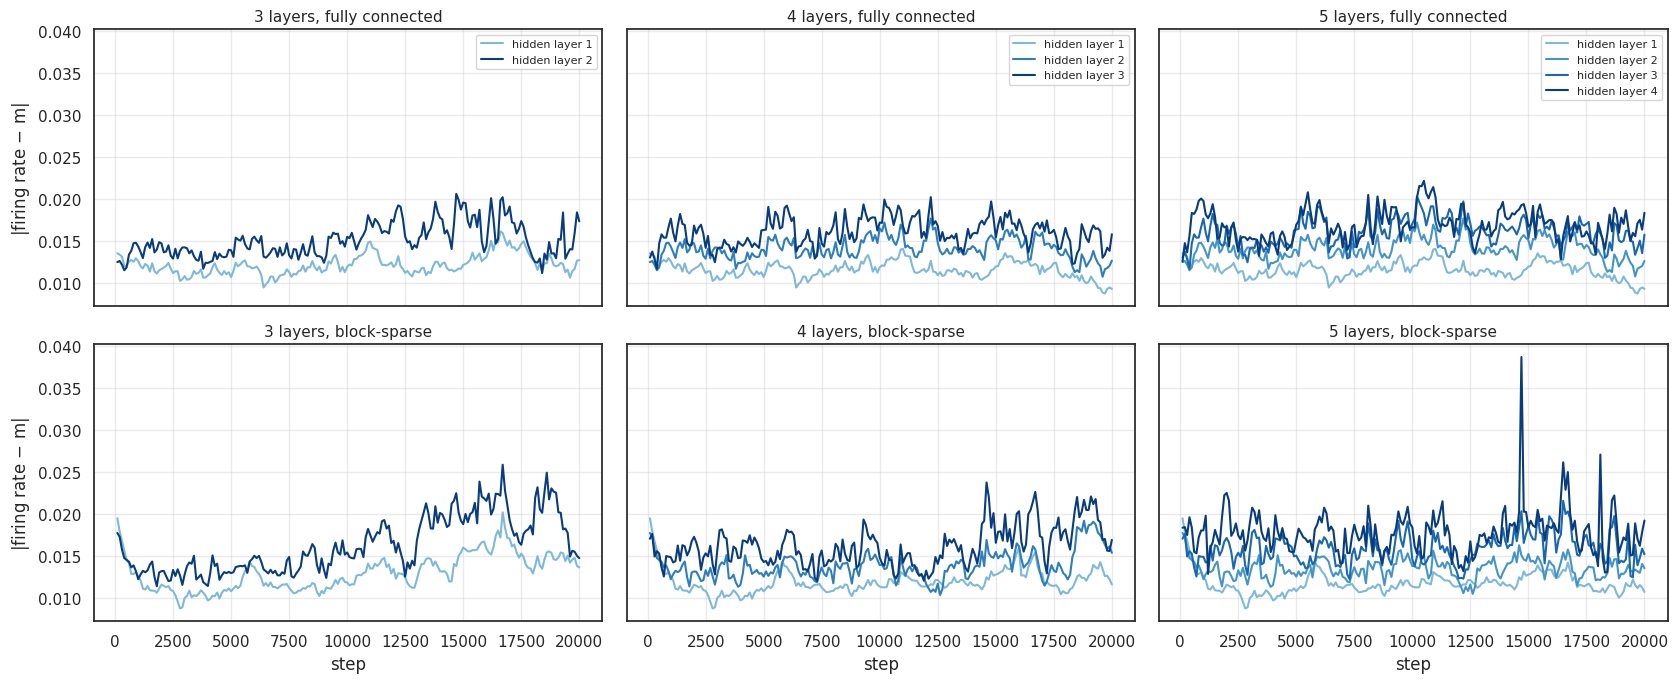

In [10]:
fig, axes = plt.subplots(2, len(DEPTHS), figsize=(17, 7), sharex=True, sharey=True)
steps = np.arange(1, EARLY_STEPS // EARLY_EVERY + 1) * EARLY_EVERY
for column, n_layers in enumerate(DEPTHS):
    for row, network in enumerate(NETWORKS):
        gaps = early_dynamics(n_layers, network).mean(0)                     # (time, hidden layer)
        ax = axes[row, column]
        for layer, color in enumerate(plt.cm.Blues(np.linspace(0.45, 0.95, n_layers - 1))):
            ax.plot(steps, gaps[:, layer], color=color, lw=1.5, label=f'hidden layer {layer + 1}')
        ax.set_title(f'{n_layers} layers, {network}', fontsize=11)
        ax.grid(alpha=0.4)
    axes[0, column].legend(fontsize=8)
    axes[1, column].set_xlabel('step')
for ax in axes[:, 0]:
    ax.set_ylabel('|firing rate $-$ m|')
fig.tight_layout()
plt.show()

## Results

- **H1 failed at every depth, by about 30 points.** Fully connected, ours reaches 48.4%, 46.4% and 45.5% online
  accuracy with 3, 4 and 5 layers, against 79.1%, 77.0% and 74.1% block-sparse: −30.7 (± 4.2), −30.6 (± 1.2) and
  −28.6 (± 1.1) points (2 SE over paired seeds). With 2 layers (05) the gap was −5.0.
- **H2 held at every depth.** Block-sparse, ours is above SGD at its best step size by +5.8 (± 2.5), +10.2 (± 2.0) and
  +24.6 (± 3.6) points; SGD reaches 73.2%, 66.8% and 49.5% (step sizes $2^{-1}$, $2^{-2}$, $2^{-2}$). From 3 to 5
  layers ours loses 5 points and SGD 24. SGD learns fast, then levels off (and slowly declines with 4 and 5 layers);
  with 5 layers ours is still rising at the end.
- **H3 held at every depth.** Fully connected, SGD (best step size $2^{-2}$ at every depth) reaches 65.3%, 45.7% and
  33.8%: −7.9 (± 3.1), −21.1 (± 3.8) and −15.7 (± 6.5) points below SGD block-sparse. Against ours fully connected
  it is 17 points better with 3 layers, level with 4 (45.7% against 46.4%), and 12 points worse with 5.
- Two things favour SGD in H2. Its main runs use the 5 seeds it was tuned on, so its numbers are the best of 9 on
  those seeds. And the powers-of-2 grid is coarse around a sharp peak (block-sparse with 4 layers: 35.7%, 66.8% and
  49.3% at $2^{-3}$, $2^{-2}$ and $2^{-1}$), so a finer grid might gain it a few points, against margins of 5.8 points
  and more. Every sweep had its best inside the starting grid ($2^{-8}$ to $2^0$), so none was extended.
- **Diagnostic 1: centering holds at depth.** Over the first 20k steps, every hidden layer's $|$true firing rate
  $- m|$ stays between 0.01 and 0.02 on both networks (one spike to 0.04), near the noise floor of about 0.011 (from
  $m$'s own noise and the probe's sampling error), against a peak of 0.22 without backward centering in
  `../01_distractors.ipynb` (3b). Higher layers sit slightly above lower ones.
- **Diagnostics 2 and 3: fully connected, ours fails by allocation, not by mixing.** Its path purity reaches 1 within
  about 30k, 70k and 150k steps, but it reads 1 because one task gets almost no paths: a task stays near chance
  (below 15% over the last 10%) in 4, 5 and 5 of the 5 seeds with 3, 4 and 5 layers, so the overall 45–48% is about
  the mean of 10% and 80%. (Each task's mean over seeds, e.g. 53.0% and 43.8% with 3 layers, averages over which task
  is dropped.) This is 05's uneven split of the hidden units, taken to the extreme. SGD fully connected does the
  opposite: it keeps both tasks (a task near chance in 0, 0 and 2 of 5 seeds) but mixes them, with path purity
  about 0.6, 0.55 and 0.55 at the end. No block-sparse run leaves a task near chance.